<html><body>
<br><br><br><br><br><br><br>
<center>
    <h1 style="font-size:48px; font-weight:normal"><b>AI</b>-TECH</h1>
    <br>
<br><br><br>
    <h1 style="font-size:24px; font-weight:normal">LABORATORIUM</h1>
    <h1 style="font-size:24px">Przetwarzanie Multimediów w<br>
Systemach Decyzyjnych
</h1>
    <h1 style="font-size:24px">LAB 06 - Segmentacja Semantyczna</h1>
    <h1 style="font-size:24px">Sebastian Cygert</h1>
    <h1 style="font-size:18px; font-weight:normal">aktualizacja 2026: Emilia Lewandowska</h1>
</center>
<br><br><br><br><br><br><br><br><br>
</body>
</html>

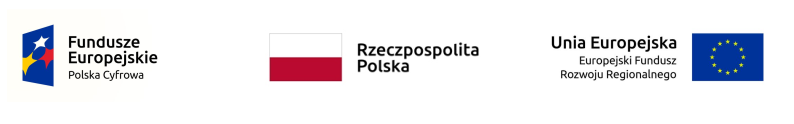

<center>
Projekt współfinansowany ze środków Unii Europejskiej w ramach Europejskiego Funduszu Rozwoju Regionalnego<br>
Program Operacyjny Polska Cyfrowa na lata 2014-2020,<br>
Oś Priorytetowa nr 3 "Cyfrowe kompetencje społeczeństwa" Działanie  nr 3.2 "Innowacyjne rozwiązania na rzecz aktywizacji cyfrowej"<br>
Tytuł projektu:  „Akademia Innowacyjnych Zastosowań Technologii Cyfrowych (AI Tech)”
</center>

# 1. Konfiguracja środowiska

W ćwiczeniu korzystamy z bibliotek **PyTorch** oraz **Hugging Face Transformers** (gotowe modele segmentacji
wytrenowane na zbiorze Cityscapes). Obie biblioteki są domyślnie zainstalowane w Google Colab, więc nie trzeba
niczego doinstalowywać ani restartować sesji.

**Google Colab:** włącz GPU: *Środowisko wykonawcze → Zmień typ środowiska wykonawczego → T4 GPU*.
Jeżeli GPU nie jest dostępne, obliczenia na CPU są wielokrotnie wolniejsze (Mask2Former: ok. 40 s na obraz) -
w takim przypadku w zadaniach 3-5 ustaw `NUM_TEST_IMGS = 5` i korzystaj z modeli SegFormer (`segformer-b0`, `segformer-b1`, `segformer-b2`).

**Praca lokalna:** `pip install torch transformers scipy opencv-python matplotlib pandas jupyter`

Przy pierwszym użyciu każdy model jest pobierany z serwisu Hugging Face Hub (od kilkunastu do kilkuset MB).
Komunikat o braku `HF_TOKEN` można zignorować.

| Biblioteka | Zastosowanie w ćwiczeniu | Odnośnik |
|---|---|---|
| torch | obliczenia na sieciach neuronowych (CPU/GPU) | https://pytorch.org |
| transformers | wytrenowane modele segmentacji semantycznej (SegFormer, Mask2Former) | https://huggingface.co/docs/transformers |
| opencv-python, numpy | wczytywanie obrazów, operacje na tablicach | https://opencv.org |
| matplotlib, pandas | wizualizacja i zestawienie wyników | https://matplotlib.org |

In [ ]:
import os
import time

import cv2
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

import torch
import torch.nn.functional as F
import transformers
from transformers import (AutoImageProcessor,
                          AutoModelForSemanticSegmentation,
                          Mask2FormerForUniversalSegmentation)

transformers.logging.set_verbosity_error()  # ukrycie nieistotnych ostrzeżeń przy wczytywaniu modeli

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| transformers', transformers.__version__, '| urządzenie:', device)
if device.type == 'cpu':
    print('UWAGA: brak GPU - obliczenia będą wolniejsze. W Colabie włącz GPU w ustawieniach środowiska.')

## Dane

Dane znajdują się w pliku `Cityscapes_walidacja.zip` dostarczonym w załączniku do laboratorium
(41 obrazów z walidacyjnej części zbioru Cityscapes, miasto Münster, w rozdzielczości 1024×512, wraz z etykietami).
Po rozpakowaniu powstaje katalog `Cityscapes/` o strukturze:
```
Cityscapes/imgs/val/munster/*_leftImg8bit.png      - obrazy
Cityscapes/labels/val/munster/*_gtFine_labelIds.png - etykiety
```

In [ ]:
# Wybierz JEDNĄ z opcji i ustaw zmienną DATA_ROOT.

# Opcja A (Colab): wgraj plik Cityscapes_walidacja.zip do sesji (ikona folderu po lewej stronie)
# i odkomentuj dwie poniższe linie:
# !unzip -q -o /content/Cityscapes_walidacja.zip -d /content
# DATA_ROOT = '/content/Cityscapes'

# Opcja B (Colab + Dysk Google): wgraj rozpakowane dane na dysk Google
# from google.colab import drive
# drive.mount('/content/gdrive')
# DATA_ROOT = '/content/gdrive/MyDrive/TODO/Cityscapes'  # tutaj ustaw odpowiednią ścieżkę

# Opcja C (lokalnie): katalog Cityscapes rozpakowany obok notebooka
DATA_ROOT = 'Cityscapes'

img_root_dir = os.path.join(DATA_ROOT, 'imgs', 'val', 'munster')
label_root_dir = os.path.join(DATA_ROOT, 'labels', 'val', 'munster')
assert os.path.isdir(img_root_dir), f'Nie znaleziono katalogu {img_root_dir} - sprawdź DATA_ROOT'

imgs = sorted(os.listdir(img_root_dir))


def label_path_for(filename):
    """Ścieżka do pliku z etykietą dla danego obrazu."""
    return os.path.join(label_root_dir, filename.replace('leftImg8bit', 'gtFine_labelIds'))


print('Liczba obrazów:', len(imgs))

## Funkcje pomocnicze (nie trzeba ich modyfikować)

* `load_image(path)` – wczytuje obraz jako tablicę **RGB** `uint8` o kształcie `(H, W, 3)`,
* `load_label(path)` – wczytuje etykietę i zamienia identyfikatory z pliku (`labelId`, 0–33) na 19 klas
  używanych w ewaluacji (`trainId`, 0–18); wartość **-1** oznacza piksele pomijane w ewaluacji
  (brak etykiety, maska samochodu nagrywającego, parking, tory, mosty, przyczepy itd.),
* `colorize(pred)` – zamienia mapę klas na kolorowy obraz (paleta Cityscapes),
* `SegmentationModel(nazwa)` – wspólny interfejs dla modeli z biblioteki `transformers`:
  * `model.predict(img)` → `np.ndarray (H, W)` z indeksem przewidywanej klasy dla każdego piksela,
  * `model.predict_proba(img)` → `torch.Tensor (19, H, W)` z prawdopodobieństwami klas.

In [ ]:
NUM_CLASSES = 19
CLASSES = ('road', 'sidewalk', 'building', 'wall', 'fence',
           'pole', 'traffic light', 'traffic sign', 'vegetation',
           'terrain', 'sky', 'person', 'rider', 'car', 'truck',
           'bus', 'train', 'motorcycle', 'bicycle')

# Oficjalne kolory klas Cityscapes (trainId 0..18)
CITYSCAPES_PALETTE = np.array([
    [128, 64, 128], [244, 35, 232], [70, 70, 70], [102, 102, 156], [190, 153, 153],
    [153, 153, 153], [250, 170, 30], [220, 220, 0], [107, 142, 35], [152, 251, 152],
    [70, 130, 180], [220, 20, 60], [255, 0, 0], [0, 0, 142], [0, 0, 70],
    [0, 60, 100], [0, 80, 100], [0, 0, 230], [119, 11, 32]], dtype=np.uint8)

# Mapowanie labelId (0..33, wartości zapisane w plikach *_gtFine_labelIds.png)
# na trainId (0..18) używane przy ewaluacji. -1 = piksel pomijany w ewaluacji
# (brak etykiety, ego vehicle, parking, tory, mosty, tunele, przyczepy itd.).
cityscapes_mapping = np.array([
    -1, -1, -1, -1, -1, -1, -1,   # 0-6:  unlabeled, ego vehicle, ..., ground
     0,  1, -1, -1,               # 7-10: road, sidewalk, parking, rail track
     2,  3,  4, -1, -1, -1,       # 11-16: building, wall, fence, guard rail, bridge, tunnel
     5, -1,  6,  7,               # 17-20: pole, polegroup, traffic light, traffic sign
     8,  9, 10,                   # 21-23: vegetation, terrain, sky
    11, 12, 13, 14, 15,           # 24-28: person, rider, car, truck, bus
    -1, -1,                       # 29-30: caravan, trailer
    16, 17, 18])                  # 31-33: train, motorcycle, bicycle


def load_image(path):
    """Wczytuje obraz jako tablicę RGB uint8 o kształcie (H, W, 3)."""
    return cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)


def load_label(path):
    """Wczytuje etykietę i zamienia labelId na trainId (-1 = ignorowany)."""
    label_ids = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    if label_ids.ndim == 3:
        label_ids = label_ids[:, :, 0]
    return cityscapes_mapping[label_ids.astype(np.int64)]


def colorize(pred):
    """Zamienia mapę trainId (H, W) na kolorowy obraz RGB."""
    out = np.zeros((*pred.shape, 3), dtype=np.uint8)
    valid = pred >= 0
    out[valid] = CITYSCAPES_PALETTE[pred[valid]]
    return out


MODEL_ZOO = {
    'segformer-b0':  'nvidia/segformer-b0-finetuned-cityscapes-1024-1024',
    'segformer-b1':  'nvidia/segformer-b1-finetuned-cityscapes-1024-1024',
    'segformer-b2':  'nvidia/segformer-b2-finetuned-cityscapes-1024-1024',
    'segformer-b5':  'nvidia/segformer-b5-finetuned-cityscapes-1024-1024',
    'mask2former-swin-tiny':  'facebook/mask2former-swin-tiny-cityscapes-semantic',
    'mask2former-swin-small': 'facebook/mask2former-swin-small-cityscapes-semantic',
}


class SegmentationModel:
    """Wspólny interfejs dla modeli SegFormer i Mask2Former.

    predict_proba(img) -> tensor (19, H, W) z prawdopodobieństwami klas
    predict(img)       -> np.ndarray (H, W) z indeksami klas (trainId)
    """

    def __init__(self, name, scale=2.0):
        self.name = name
        self.scale = scale  # obrazy w zbiorze mają 1024x512 (połowa rozdzielczości Cityscapes)
        repo = MODEL_ZOO.get(name, name)
        self.processor = AutoImageProcessor.from_pretrained(repo)
        self.is_mask2former = 'mask2former' in repo.lower()
        if self.is_mask2former:
            self.model = Mask2FormerForUniversalSegmentation.from_pretrained(repo)
        else:
            self.model = AutoModelForSemanticSegmentation.from_pretrained(repo)
        self.model.to(device).eval()

    @torch.no_grad()
    def predict_proba(self, img):
        h, w = img.shape[:2]
        size = {'height': int(h * self.scale), 'width': int(w * self.scale)}
        inputs = self.processor(images=img, size=size, return_tensors='pt').to(device)
        out = self.model(**inputs)
        if self.is_mask2former:
            cls = out.class_queries_logits.softmax(-1)[..., :-1]      # (1, Q, 19), bez klasy "brak obiektu"
            masks = out.masks_queries_logits.sigmoid()               # (1, Q, h', w')
            scores = torch.einsum('bqc,bqhw->bchw', cls, masks)
            scores = F.interpolate(scores, size=(h, w), mode='bilinear', align_corners=False)
            probs = scores / scores.sum(1, keepdim=True).clamp_min(1e-8)
        else:
            logits = F.interpolate(out.logits, size=(h, w), mode='bilinear', align_corners=False)
            probs = logits.softmax(1)
        return probs[0]

    def predict(self, img):
        return self.predict_proba(img).argmax(0).cpu().numpy()

# 2. Wczytanie wytrenowanego modelu na zbiorze Cityscapes

Korzystamy z modeli udostępnionych w serwisie Hugging Face Hub (https://huggingface.co/models), wytrenowanych na zbiorze Cityscapes.
Słownik `MODEL_ZOO` zawiera przygotowane modele:

| Nazwa | Architektura | Liczba parametrów |
|---|---|---|
| `segformer-b0` | SegFormer (enkoder MiT-B0), https://huggingface.co/nvidia/segformer-b0-finetuned-cityscapes-1024-1024 | 3.7 mln |
| `segformer-b1` | SegFormer (enkoder MiT-B1) | 13.7 mln |
| `segformer-b2` | SegFormer (enkoder MiT-B2) | 27.4 mln |
| `segformer-b5` | SegFormer (enkoder MiT-B5) | 84.6 mln |
| `mask2former-swin-tiny` | Mask2Former (enkoder Swin-T), https://huggingface.co/facebook/mask2former-swin-tiny-cityscapes-semantic | 47.4 mln |
| `mask2former-swin-small` | Mask2Former (enkoder Swin-S) | 68.7 mln |

Ze względu na czas działania polecane są mniejsze modele (`segformer-b0`, `segformer-b1`, `segformer-b2`, `mask2former-swin-tiny`).
Model `segformer-b5` jest jednym z najdokładniejszych, ale też jednym z najwolniejszych.

SegFormer przypisuje klasę każdemu pikselowi (podobnie jak FCN czy DeepLab), natomiast Mask2Former przewiduje zbiór
masek wraz z ich klasami, które są następnie łączone w mapę segmentacji. Klasa `SegmentationModel` ukrywa te różnice.

Modele były trenowane na obrazach w pełnej rozdzielczości Cityscapes (2048×1024), dlatego nasze obrazy (1024×512)
są przed podaniem do sieci powiększane dwukrotnie (parametr `scale=2.0`), a predykcja skalowana z powrotem do rozmiaru obrazu.

In [ ]:
model = SegmentationModel('segformer-b0')
print('Liczba parametrów: %.1f mln' % (sum(p.numel() for p in model.model.parameters()) / 1e6))

Uruchomienie modelu na przykładowym obrazie

In [ ]:
filepath = os.path.join(img_root_dir, 'munster_000000_000019_leftImg8bit.png')

img = load_image(filepath)
predict = model.predict(img)  # indeks przewidywanej klasy dla każdego piksela
print(img.shape, predict.shape, predict.dtype)

In [ ]:
# wyświetlenie obrazu, maski oraz nałożenia maski na obraz
mask = colorize(predict)
overlay = cv2.addWeighted(img, 0.5, mask, 0.5, 0)

fig, axes = plt.subplots(3, 1, figsize=(12, 18))
for ax, im, title in zip(axes, [img, mask, overlay], ['Obraz', 'Predykcja', 'Nałożenie']):
    ax.imshow(im)
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

# Zadanie 1. Obliczenie metryki pixel accuracy [1 pkt.]

W tym ćwiczeniu Twoim zadaniem jest uzupełnienie kodu funkcji `compute_pix_acc` obliczającej proporcję poprawnie sklasyfikowanych pikseli.
W funkcji należy ignorować piksele, dla których etykieta (`label`) wynosi -1.
Oczekiwana wartość dla modelu `segformer-b0` wynosi około 97%.

In [ ]:
def compute_pix_acc(prediction, label):
    total_pixels = TODO
    correct_pixels = TODO
    return correct_pixels / total_pixels

In [ ]:
filename = imgs[0]
img = load_image(os.path.join(img_root_dir, filename))
label = load_label(label_path_for(filename))

predict = model.predict(img)
pix_acc = compute_pix_acc(predict, label)
print(filename, 'pixel accuracy: %.4f' % pix_acc)

---
### Odpowiedzi i wnioski – Zadanie 1
*(uzupełnij: kliknij dwukrotnie komórkę, aby ją edytować)*

**Wnioski:** ...

# Zadanie 2. Metryka IoU dla klas i meanIoU [2 pkt.]

**a)** Uzupełnij funkcję `compute_iou_per_class`, która dla każdej z 19 klas oblicza Intersection over Union:
$IoU = \frac{TP}{TP + FP + FN}$. Przyjmij, że do ewaluacji bierzemy tylko klasy, które posiadają więcej niż `min_pixels`
(domyślnie 1500) pikseli w pliku etykiet (aby usunąć nieistotne obiekty) - dla pozostałych klas zwróć `np.nan`.
Pamiętaj, że piksele z etykietą -1 nie są brane pod uwagę (również przy liczeniu FP).
Następnie uzupełnij funkcję `compute_miou` zwracającą średnią IoU po ocenianych klasach.

Oczekiwana wartość mIoU dla modelu `segformer-b0` na tym samym obrazie wynosi około 0.81.

**b)** Uśrednianie mIoU po obrazach nie jest jedynym sposobem liczenia tej metryki. W oficjalnej ewaluacji Cityscapes
zlicza się **macierz pomyłek** (ang. *confusion matrix*) dla całego zbioru danych, a IoU każdej klasy liczy się
dopiero z sumarycznych wartości TP, FP i FN. Uzupełnij funkcje:
* `compute_confusion_matrix(prediction, label)` - zwraca macierz `(19, 19)`, w której element `[i, j]` to liczba pikseli
  klasy `i` (etykieta) zaklasyfikowanych jako klasa `j` (predykcja); piksele z etykietą -1 pomijamy,
* `iou_from_confusion(cm)` - zwraca tablicę `(19,)` z IoU każdej klasy (`np.nan` dla klas, które nie występują ani w etykietach, ani w predykcjach).

Poprawność obu implementacji możesz sprawdzić w komórce testowej - dla klas obecnych na obrazie wyniki muszą być identyczne.

In [ ]:
def compute_iou_per_class(prediction, label, min_pixels=1500):
    ious = np.full(NUM_CLASSES, np.nan)
    for class_id in range(NUM_CLASSES):
        tp = TODO
        fp = TODO
        fn = TODO
        target_pix = np.sum(label == class_id)
        if target_pix > min_pixels:
            ious[class_id] = TODO
    return ious


def compute_miou(prediction, label):
    return TODO


def compute_confusion_matrix(prediction, label):
    # TODO
    pass


def iou_from_confusion(cm):
    # TODO
    pass

In [ ]:
miou = compute_miou(predict, label)
print(filename, 'mIoU: %.4f' % miou)

# test zgodności obu implementacji (dla klas obecnych w etykiecie)
present = np.unique(label[label >= 0])
ious_img = compute_iou_per_class(predict, label, min_pixels=0)
ious_cm = iou_from_confusion(compute_confusion_matrix(predict, label))
print('Zgodność obu implementacji:', np.allclose(ious_img[present], ious_cm[present]))

pd.DataFrame({'IoU': ious_img[present]}, index=[CLASSES[c] for c in present]).round(3).T

---
### Odpowiedzi i wnioski – Zadanie 2
*(uzupełnij: kliknij dwukrotnie komórkę, aby ją edytować)*

**Wnioski:** ...

# Zadanie 3. Porównanie dokładności i szybkości modeli [2 pkt.]

**a)** Napisz funkcję `evaluate(model, num_imgs)`, która dla pierwszych `num_imgs` obrazów zbioru zwraca słownik z:
* `pix_acc` - średnia pixel accuracy po obrazach,
* `mIoU` - średnie mIoU po obrazach (funkcja `compute_miou`),
* `mIoU_dataset` - mIoU liczone z macierzy pomyłek zsumowanej po wszystkich ocenianych obrazach,
* `FPS` - liczba przetwarzanych obrazów na sekundę (mierz wyłącznie czas wywołania `model.predict`;
  pierwsze wywołanie na GPU jest wolniejsze, więc przed pomiarem wykonaj jedną predykcję "na rozgrzewkę"),
* `iou_per_class` - tablica IoU dla każdej klasy (z macierzy pomyłek).

**b)** Oblicz metryki dla **co najmniej 3 modeli** z `MODEL_ZOO` i zestaw wyniki w tabeli.
Przygotuj wykres zależności mIoU od FPS (kompromis między dokładnością a szybkością) oraz wykres IoU dla poszczególnych klas
dla wybranych modeli.

Uwaga: wartości FPS zależą od sprzętu (w Colabie - od przydzielonego GPU), dlatego w sprawozdaniu podaj, na jakim sprzęcie wykonano pomiar.
Jeżeli pracujesz bez GPU, ustaw `NUM_TEST_IMGS = 5` i wybierz modele SegFormer (Mask2Former na CPU potrzebuje ok. 40 s na obraz).

**Pytania do sprawozdania:**
1. Dlaczego pixel accuracy jest wyraźnie wyższe niż mIoU? Które klasy są najtrudniejsze dla modeli i z czego to może wynikać?
2. Czym różnią się wartości `mIoU` i `mIoU_dataset`? Która z nich jest stosowana w benchmarkach i dlaczego? Jaki wpływ na wynik ma próg 1500 pikseli?
3. Który z badanych modeli wybrałbyś/wybrałabyś do systemu działającego w samochodzie w czasie rzeczywistym, a który do automatycznego
   przygotowywania etykiet (offline)? Uzasadnij.

In [ ]:
NUM_TEST_IMGS = 20  # mniejsza liczba przyspiesza debugowanie (cały zbiór: 41 obrazów)


def evaluate(model, num_imgs=NUM_TEST_IMGS):
    # TODO
    pass


# TODO: ewaluacja co najmniej 3 modeli, tabela wyników, wykresy

In [ ]:
# TODO: wykres mIoU w funkcji FPS oraz wykres IoU dla poszczególnych klas

---
### Odpowiedzi i wnioski – Zadanie 3
*(uzupełnij: kliknij dwukrotnie komórkę, aby ją edytować)*

**Pytanie 1:** ...

**Pytanie 2:** ...

**Pytanie 3:** ...

**Wnioski:** ...

# Zadanie 4. Odporność modeli na zakłócenia obrazu [2 pkt.]

**a)** Rozszerz funkcję `evaluate` tak, aby przed predykcją można było zastosować do obrazu dowolne zakłócenie
(np. przekazując funkcję jako argument). Zakłócenie dotyczy tylko obrazu wejściowego - etykiety pozostają bez zmian.

**b)** Dla 2 wybranych modeli wyznacz i przedstaw na wykresie zależność mIoU od wariancji szumu gaussowskiego
(np. dla wariancji 0, 50, 100, 200, 400 i 800). Wykorzystaj poniższą funkcję `add_noise` (z poprzedniego ćwiczenia laboratoryjnego).

**c)** Zaimplementuj **drugi typ zakłócenia**, częściej spotykany w praktyce: rozmycie obrazu (np. `cv2.GaussianBlur`,
symulujące nieostrość lub ruch kamery) albo stratną kompresję JPEG (`cv2.imencode` / `cv2.imdecode`, symulującą transmisję obrazu).
Zbadaj wpływ tego zakłócenia na oba modele dla 2 poziomów jego intensywności.

Wyniki dopisz do tabeli z poprzedniego zadania.

Wskazówka: szum jest losowy, więc wyniki różnią się nieco między uruchomieniami. Aby były powtarzalne, ustaw ziarno
generatora liczb losowych (np. `np.random.seed(0)`) przed każdą ewaluacją z szumem.

**Pytania do sprawozdania:**
1. Który model jest bardziej odporny na zakłócenia? Porównaj względny (procentowy) spadek mIoU, a nie tylko wartości bezwzględne.
2. Czy odporność zależy od wielkości / architektury modelu? Które klasy tracą najwięcej?
3. Jakie znaczenie mają te wyniki przy wdrażaniu modelu w rzeczywistym systemie i jak można zwiększyć odporność modelu?

In [ ]:
# Definicja funkcji dodającej szum gaussowski
def add_noise(input_img, var=0.0):
    mean = 0.0
    sigma = var ** 0.5
    gauss = np.random.normal(mean, sigma, input_img.shape)
    # Dodaj szum do obrazu (obliczenia na liczbach zmiennoprzecinkowych, a następnie przycięcie do zakresu 0-255)
    img_gauss = np.clip(input_img.astype(np.float32) + gauss, 0, 255).astype(np.uint8)
    return img_gauss

In [ ]:
# podgląd obrazu z szumem
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, var in zip(axes, [0, 100, 400]):
    ax.imshow(add_noise(img, var))
    ax.set_title(f'wariancja = {var}')
    ax.axis('off')
plt.show()

In [ ]:
# TODO: b) zależność mIoU od wariancji szumu dla 2 modeli (wykres)

In [ ]:
# TODO: c) drugi typ zakłócenia (rozmycie lub kompresja JPEG) dla 2 poziomów intensywności

---
### Odpowiedzi i wnioski – Zadanie 4
*(uzupełnij: kliknij dwukrotnie komórkę, aby ją edytować)*

**Pytanie 1:** ...

**Pytanie 2:** ...

**Pytanie 3:** ...

**Wnioski:** ...

# Zadanie 5. Model ensembling [3 pkt.]
W tym ćwiczeniu wykorzystamy wiele modeli (model ensembling) do poprawy dokładności działania modelu.

**a)** Uzupełnij klasę `Ensemble`, implementując dwie strategie łączenia predykcji:
* `'mean'` - uśrednienie rozkładów prawdopodobieństwa klas zwracanych przez modele,
* `'vote'` - głosowanie większościowe (każdy model "głosuje" na jedną klasę dla każdego piksela); zastanów się, jak rozstrzygać remisy.

Klasa powinna mieć metodę `predict` o takim samym interfejsie jak pojedynczy model, aby można ją było przekazać do funkcji `evaluate`.

**b)** Porównaj obie strategie dla zespołu **3 modeli** (zwróć uwagę na czas przetwarzania) - bez zakłóceń oraz z szumem
gaussowskim (jedna z wariancji z zadania 4). Porównaj wyniki z najlepszym pojedynczym modelem.

W sprawozdaniu wklej kawałek kodu odpowiedzialny za agregację wyników.

**Pytania do sprawozdania:**
1. Kiedy ensembling poprawia wyniki, a kiedy nie? Czy zespół może być gorszy od swojego najlepszego członka - dlaczego?
2. Która strategia łączenia działa lepiej i dlaczego? Jakie inne strategie można zastosować (np. ważenie modeli)?
3. Czy poprawa dokładności jest warta spadku FPS? W jakich zastosowaniach tak, a w jakich nie?

In [ ]:
class Ensemble:
    def __init__(self, models, strategy='mean'):
        self.models = models
        self.strategy = strategy

    def predict(self, img):
        # TODO: zwróć mapę klas (H, W) jako np.ndarray
        pass


# TODO: porównanie strategii 'mean' i 'vote' dla 3 modeli (bez zakłóceń i z szumem), wyniki dopisz do tabeli

---
### Odpowiedzi i wnioski – Zadanie 5
*(uzupełnij: kliknij dwukrotnie komórkę, aby ją edytować)*

**Pytanie 1:** ...

**Pytanie 2:** ...

**Pytanie 3:** ...

**Wnioski:** ...

---
# Podsumowanie

*(uzupełnij)* Najważniejsze wnioski z całego ćwiczenia (3–5 zdań): który model wybrałbyś/wybrałabyś i do jakiego
zastosowania, jak zakłócenia obrazu wpływają na jakość segmentacji oraz czy ensembling jest wart swojego kosztu obliczeniowego.

...